# 01 — Preparação dos Dados e Fine-Tuning com LoRA

Este notebook executa o pipeline completo de treinamento:
1. **Geração Procedural de Dados Sintéticos** (com gabarito exato via `datetime` do Python).
2. **Configuração da LLM Base** (`Qwen/Qwen3-1.7B` em `bfloat16`) e máscara de perda (`-100` nos tokens de instrução).
3. **Treinamento Comparativo de Parâmetros LoRA**:
   - Experimento 1: LoRA r = 8, alpha = 16 (8.7M parâmetros treináveis)
   - Experimento 2: LoRA r = 16, alpha = 32 (17.4M parâmetros treináveis — modelo principal)
4. **Curvas de Loss (Train Loss e Validation Loss)** salvas em `assets/curva_loss_comparacao.png`.


In [11]:
# ==============================================================================
# CONTROLE DE EXECUÇÃO RÁPIDA (FAST-SKIP)
# ==============================================================================
# Se False: Carrega o histórico pré-computado de results/ e gera os gráficos em segundos.
# Se True:  Executa o fine-tuning real de LoRA (r=8 e r=16) na GPU por 3 épocas.
REEXECUTAR_TREINO = True


## 1. Geração Procedural dos Datasets (Treino, Validação e Teste)


In [12]:
import pandas as pd

from gerar_dados import FAMILIAS_INEDITAS, FAMILIAS_TREINO, gerar_dataset

# Gera o dataset padrão ou permite parametrizar tamanhos para testes rápidos
# Exemplo para teste enxuto: gerar_dataset(n_treino=500, n_val=50)
dados = gerar_dataset(
    n_treino=2600,
    n_val=260,
    n_teste_variacao=260,
    n_teste_inedita=100,
    seed=42,
)

print("=" * 60)
print("Dataset gerado e pronto para o treinamento:")
print(f"  - Treino:    {len(dados['treino'])} exemplos ({len(FAMILIAS_TREINO)} famílias conhecidas)")
print(f"  - Validação: {len(dados['validacao'])} exemplos ({len(FAMILIAS_TREINO)} famílias conhecidas)")
print(f"  - Teste:     {len(dados['teste'])} exemplos (260 variações + {len(FAMILIAS_INEDITAS) * 25} famílias inéditas)")
print("=" * 60)

# Amostra dos dados gerados
df_amostra = pd.DataFrame(dados["treino"][:5])
df_amostra[["familia", "referencia", "expressao", "resposta"]]


Dataset gerado e pronto para o treinamento:
  - Treino:    2600 exemplos (13 famílias conhecidas)
  - Validação: 260 exemplos (13 famílias conhecidas)
  - Teste:     360 exemplos (260 variações + 100 famílias inéditas)


,familia,referencia,expressao,resposta
0,daqui_dias,2026-02-03T15:55,daqui a 2 dias às 9:05,2026-02-05T09:05
1,daqui_semanas,2026-10-27T10:05,dentro de oito semanas,2026-12-22
2,daqui_meses,2027-09-17T15:15,em 7 meses,2028-04-17
3,daqui_semanas,2025-12-31T17:35,dentro de oito semanas,2026-02-25
4,dia_relativo,2024-03-14T09:15,depois de amanhã,2024-03-16


## 2. Configuração do Modelo Base e Tokenização com Loss Masking

Tokens de prompt e padding recebem rótulo `-100`, calculando o gradiente exclusivamente sobre a resposta ISO 8601.


In [13]:
import gc
import json
import random
import shutil
import time

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import Dataset
from peft import LoraConfig, TaskType, get_peft_model
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    Trainer,
    TrainingArguments,
    default_data_collator,
)

from common import (
    BASE,
    DIR_ADAPTERS,
    DIR_ASSETS,
    DIR_RESULTS,
    escolher_device,
    ler_jsonl,
    prompt_chat,
)

# Sementes para reprodutibilidade
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [14]:
device = escolher_device()
print(f"Dispositivo de treinamento: {device}")
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"VRAM Livre inicial: {torch.cuda.mem_get_info()[0] / (1024**3):.2f} GB")

Dispositivo de treinamento: cuda
GPU: NVIDIA GeForce RTX 3060 Ti
VRAM Livre inicial: 6.97 GB


In [15]:
dados_treino = ler_jsonl("treino")
dados_validacao = ler_jsonl("validacao")

print(f"Exemplos de treino:    {len(dados_treino)}")
print(f"Exemplos de validação: {len(dados_validacao)}")

Exemplos de treino:    2600
Exemplos de validação: 260


In [16]:
tokenizer = AutoTokenizer.from_pretrained(BASE)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"  # no treinamento, padding à direita facilita o collator

MAX_LENGTH = 160


def tokenizar_item(exemplo):
    prompt = prompt_chat(tokenizer, exemplo["referencia"], exemplo["expressao"])
    resposta = exemplo["resposta"] + tokenizer.eos_token
    texto_completo = prompt + resposta

    tokens = tokenizer(
        texto_completo,
        add_special_tokens=False,
        truncation=True,
        max_length=MAX_LENGTH,
        padding="max_length",
    )

    tokens_prompt = tokenizer(
        prompt,
        add_special_tokens=False,
        truncation=True,
        max_length=MAX_LENGTH,
    )["input_ids"]

    labels = tokens["input_ids"].copy()
    limite_prompt = min(len(tokens_prompt), MAX_LENGTH)
    labels[:limite_prompt] = [-100] * limite_prompt

    labels = [
        label if mascara == 1 else -100
        for label, mascara in zip(labels, tokens["attention_mask"])
    ]
    tokens["labels"] = labels
    return tokens


ds_treino = Dataset.from_list(dados_treino).map(tokenizar_item, remove_columns=list(dados_treino[0].keys()))
ds_validacao = Dataset.from_list(dados_validacao).map(tokenizar_item, remove_columns=list(dados_validacao[0].keys()))

print("Tamanho do lote de treino tokenizado:", len(ds_treino))
print("Tamanho do lote de validação tokenizado:", len(ds_validacao))
print("Comprimento da sequência:", len(ds_treino[0]["input_ids"]))
n_alvo = sum(x != -100 for x in ds_treino[0]["labels"])
print(f"Tokens de resposta cobrados no 1º exemplo: {n_alvo} tokens")

Map: 100%|██████████| 260/260 [00:00<00:00, 2321.43 examples/s]

Tamanho do lote de treino tokenizado: 2600
Tamanho do lote de validação tokenizado: 260
Comprimento da sequência: 160
Tokens de resposta cobrados no 1º exemplo: 17 tokens


In [17]:
TARGET_MODULES = [
    "q_proj",
    "k_proj",
    "v_proj",
    "o_proj",
    "gate_proj",
    "up_proj",
    "down_proj",
]


def treinar_experimento(nome_exp, r, lora_alpha, num_epocas=3, lr=2e-4):
    print("\n" + "=" * 60)
    print(f"INICIANDO {nome_exp}: LoRA r={r}, alpha={lora_alpha}, lr={lr}, {num_epocas} épocas")
    print("=" * 60)

    # Limpar memória GPU
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # Carregar modelo base limpo em bfloat16
    model = AutoModelForCausalLM.from_pretrained(
        BASE,
        dtype=torch.bfloat16 if device == "cuda" else torch.float32,
    ).to(device)

    config_lora = LoraConfig(
        r=r,
        lora_alpha=lora_alpha,
        lora_dropout=0.05,
        bias="none",
        task_type=TaskType.CAUSAL_LM,
        target_modules=TARGET_MODULES,
    )

    model = get_peft_model(model, config_lora)
    model.config.use_cache = False
    model.enable_input_require_grads()
    if device == "cuda":
        model.gradient_checkpointing_enable()

    print("Parâmetros do modelo com LoRA:")
    model.print_trainable_parameters()

    output_dir = f"./checkpoints_{nome_exp}"
    shutil.rmtree(output_dir, ignore_errors=True)

    args_treino = TrainingArguments(
        output_dir=output_dir,
        num_train_epochs=num_epocas,
        per_device_train_batch_size=4,
        per_device_eval_batch_size=4,
        gradient_accumulation_steps=4,  # tamanho efetivo de lote = 16
        learning_rate=lr,
        warmup_steps=20,
        weight_decay=0.01,
        logging_steps=10,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        save_total_limit=1,
        bf16=(device == "cuda"),
        report_to="none",
        seed=SEED,
        optim="adamw_torch",
    )

    trainer = Trainer(
        model=model,
        args=args_treino,
        train_dataset=ds_treino,
        eval_dataset=ds_validacao,
        data_collator=default_data_collator,
    )

    inicio_t = time.time()
    trainer.train()
    duracao = time.time() - inicio_t
    print(f"Treino de {nome_exp} concluído em {duracao:.1f} s")

    # Salvar adaptador LoRA
    caminho_salvar = DIR_ADAPTERS / nome_exp
    caminho_salvar.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(str(caminho_salvar))
    tokenizer.save_pretrained(str(caminho_salvar))
    print(f"Adaptador LoRA salvo em: {caminho_salvar}")

    # Coletar histórico de logs
    log_history = trainer.state.log_history

    # Limpeza de memória
    del model, trainer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    shutil.rmtree(output_dir, ignore_errors=True)
    return log_history, duracao


## 3. Experimento 1: Treinamento LoRA r=8, alpha=16


In [18]:
caminho_hist = DIR_RESULTS / "historico_treino.json"
caminho_pesos_r8 = DIR_ADAPTERS / "lora_r8"

if not REEXECUTAR_TREINO and caminho_pesos_r8.exists() and caminho_hist.exists():
    print("[FAST-SKIP] REEXECUTAR_TREINO=False: Carregando histórico pré-computado para LoRA r=8...")
    with open(caminho_hist, encoding="utf-8") as f:
        hist_salvo = json.load(f)
    logs_exp1 = hist_salvo["lora_r8"]["logs"]
    dur_exp1 = hist_salvo["lora_r8"]["duracao_s"]
    print(f"Histórico r=8 pronto ({len(logs_exp1)} registros de log, {dur_exp1:.1f} s de treino original).")
else:
    logs_exp1, dur_exp1 = treinar_experimento("lora_r8", r=8, lora_alpha=16, num_epocas=3, lr=2e-4)



INICIANDO lora_r8: LoRA r=8, alpha=16, lr=0.0002, 3 épocas


Loading weights: 100%|██████████| 311/311 [00:03<00:00, 88.70it/s]


Parâmetros do modelo com LoRA:
trainable params: 8,716,288 || all params: 1,729,291,264 || trainable%: 0.5040


Epoch,Training Loss,Validation Loss
1,0.062201,0.055462
2,0.031871,0.039614
3,0.015499,0.033197


Treino de lora_r8 concluído em 1089.1 s
Adaptador LoRA salvo em: F:\CP5GenAI\adapters\lora_r8


## 4. Experimento 2: Treinamento LoRA r=16, alpha=32 (Modelo Principal)


In [19]:
caminho_pesos_r16 = DIR_ADAPTERS / "lora_r16"

if not REEXECUTAR_TREINO and caminho_pesos_r16.exists() and caminho_hist.exists():
    print("[FAST-SKIP] REEXECUTAR_TREINO=False: Carregando histórico pré-computado para LoRA r=16...")
    with open(caminho_hist, encoding="utf-8") as f:
        hist_salvo = json.load(f)
    logs_exp2 = hist_salvo["lora_r16"]["logs"]
    dur_exp2 = hist_salvo["lora_r16"]["duracao_s"]
    print(f"Histórico r=16 pronto ({len(logs_exp2)} registros de log, {dur_exp2:.1f} s de treino original).")
else:
    logs_exp2, dur_exp2 = treinar_experimento("lora_r16", r=16, lora_alpha=32, num_epocas=3, lr=2e-4)

print(f"Adaptador r=16 (Modelo Principal) disponível em: {caminho_pesos_r16}")



INICIANDO lora_r16: LoRA r=16, alpha=32, lr=0.0002, 3 épocas


Loading weights: 100%|██████████| 311/311 [00:01<00:00, 275.37it/s]


Parâmetros do modelo com LoRA:
trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030


Epoch,Training Loss,Validation Loss
1,0.066587,0.069112
2,0.029848,0.040276
3,0.011355,0.027983


Treino de lora_r16 concluído em 1095.4 s
Adaptador LoRA salvo em: F:\CP5GenAI\adapters\lora_r16
Adaptador r=16 (Modelo Principal) disponível em: F:\CP5GenAI\adapters\lora_r16


## 5. Curvas Comparativas de Aprendizado (Train Loss e Eval Loss)


Gráfico de comparação salvo em: F:\CP5GenAI\assets\curva_loss_comparacao.png


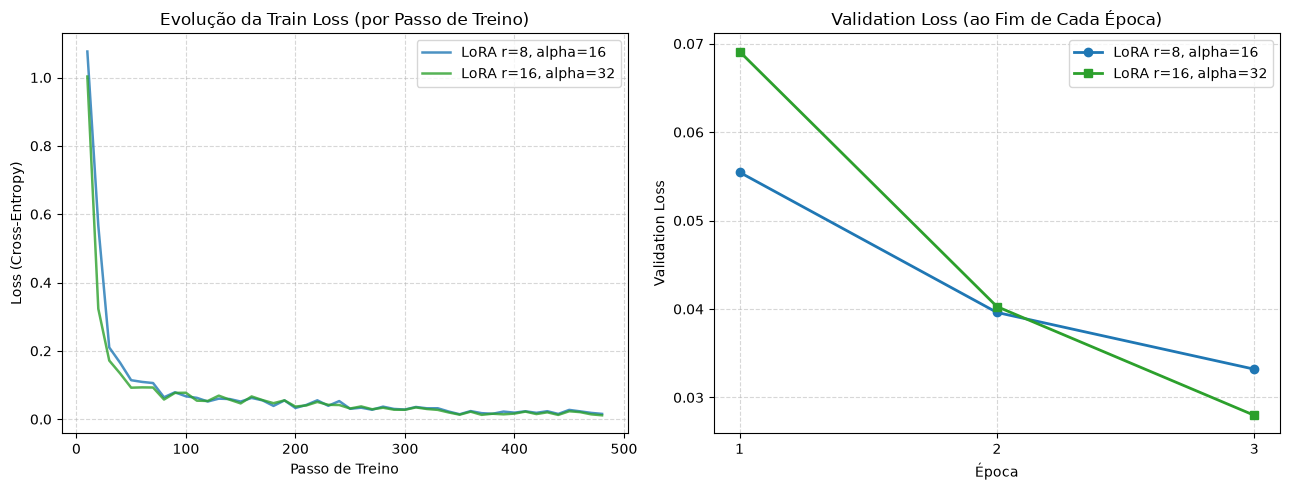

Histórico de treino salvo em: F:\CP5GenAI\results\historico_treino.json


In [20]:
def extrair_curvas(logs):
    treino_steps, treino_loss = [], []
    eval_epochs, eval_loss = [], []
    for l in logs:
        if "loss" in l and "step" in l:
            treino_steps.append(l["step"])
            treino_loss.append(l["loss"])
        if "eval_loss" in l and "epoch" in l:
            eval_epochs.append(round(l["epoch"]))
            eval_loss.append(l["eval_loss"])
    return treino_steps, treino_loss, eval_epochs, eval_loss


t_step1, t_loss1, e_ep1, e_loss1 = extrair_curvas(logs_exp1)
t_step2, t_loss2, e_ep2, e_loss2 = extrair_curvas(logs_exp2)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Train Loss ao longo dos passos
axes[0].plot(t_step1, t_loss1, label="LoRA r=8, alpha=16", color="#1f77b4", alpha=0.8, linewidth=1.8)
axes[0].plot(t_step2, t_loss2, label="LoRA r=16, alpha=32", color="#2ca02c", alpha=0.8, linewidth=1.8)
axes[0].set_title("Evolução da Train Loss (por Passo de Treino)")
axes[0].set_xlabel("Passo de Treino")
axes[0].set_ylabel("Loss (Cross-Entropy)")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend()

# Subplot 2: Validation Loss ao final de cada época
axes[1].plot(e_ep1, e_loss1, "o-", label="LoRA r=8, alpha=16", color="#1f77b4", linewidth=2)
axes[1].plot(e_ep2, e_loss2, "s-", label="LoRA r=16, alpha=32", color="#2ca02c", linewidth=2)
axes[1].set_title("Validation Loss (ao Fim de Cada Época)")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Validation Loss")
axes[1].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend()

plt.tight_layout()
caminho_grafico = DIR_ASSETS / "curva_loss_comparacao.png"
plt.savefig(caminho_grafico, dpi=150)
print(f"Gráfico de comparação salvo em: {caminho_grafico}")
plt.show()

# Salvar dados de histórico em JSON para documentação
DIR_RESULTS.mkdir(exist_ok=True)
historico_treino = {
    "lora_r8": {"duracao_s": dur_exp1, "logs": logs_exp1},
    "lora_r16": {"duracao_s": dur_exp2, "logs": logs_exp2},
}
with open(DIR_RESULTS / "historico_treino.json", "w", encoding="utf-8") as f:
    json.dump(historico_treino, f, indent=2)
print(f"Histórico de treino salvo em: {DIR_RESULTS / 'historico_treino.json'}")
